# 01 Spambase: spam vs ham
New dataset: change `DATA` and `TARGET`.

## 1. Setup

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import friedmanchisquare, f_oneway, ttest_rel, wilcoxon
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")

from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.utils import resample
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

In [2]:
DATA = "data/spambase.csv"
TARGET = "class"
AVG = "binary"
SCORING = "accuracy"

In [3]:
df = pd.read_csv(DATA)
df.shape

(4601, 58)

## 2. EDA

In [4]:
df.head()

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_semicolon,char_freq_open_paren,char_freq_open_bracket,char_freq_exclamation,char_freq_dollar,char_freq_hash,capital_run_length_average,capital_run_length_longest,capital_run_length_total,class
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4601 entries, 0 to 4600
Data columns (total 58 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   word_freq_make              4601 non-null   float64
 1   word_freq_address           4601 non-null   float64
 2   word_freq_all               4601 non-null   float64
 3   word_freq_3d                4601 non-null   float64
 4   word_freq_our               4601 non-null   float64
 5   word_freq_over              4601 non-null   float64
 6   word_freq_remove            4601 non-null   float64
 7   word_freq_internet          4601 non-null   float64
 8   word_freq_order             4601 non-null   float64
 9   word_freq_mail              4601 non-null   float64
 10  word_freq_receive           4601 non-null   float64
 11  word_freq_will              4601 non-null   float64
 12  word_freq_people            4601 non-null   float64
 13  word_freq_report            4601 non-null   

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
word_freq_make,4601.0,0.104553,0.305358,0.0,0.000,0.000,0.000,4.540
word_freq_address,4601.0,0.213015,1.290575,0.0,0.000,0.000,0.000,14.280
word_freq_all,4601.0,0.280656,0.504143,0.0,0.000,0.000,0.420,5.100
word_freq_3d,4601.0,0.065425,1.395151,0.0,0.000,0.000,0.000,42.810
word_freq_our,4601.0,0.312223,0.672513,0.0,0.000,0.000,0.380,10.000
word_freq_over,4601.0,0.095901,0.273824,0.0,0.000,0.000,0.000,5.880
word_freq_remove,4601.0,0.114208,0.391441,0.0,0.000,0.000,0.000,7.270
word_freq_internet,4601.0,0.105295,0.401071,0.0,0.000,0.000,0.000,11.110
word_freq_order,4601.0,0.090067,0.278616,0.0,0.000,0.000,0.000,5.260
word_freq_mail,4601.0,0.239413,0.644755,0.0,0.000,0.000,0.160,18.180


In [7]:
print(df.isnull().sum().sum())
print(df.duplicated().sum())

0
391


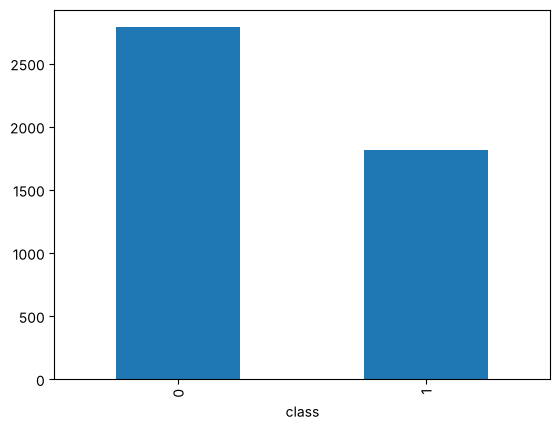

In [8]:
df[TARGET].value_counts().plot(kind="bar")
plt.show()

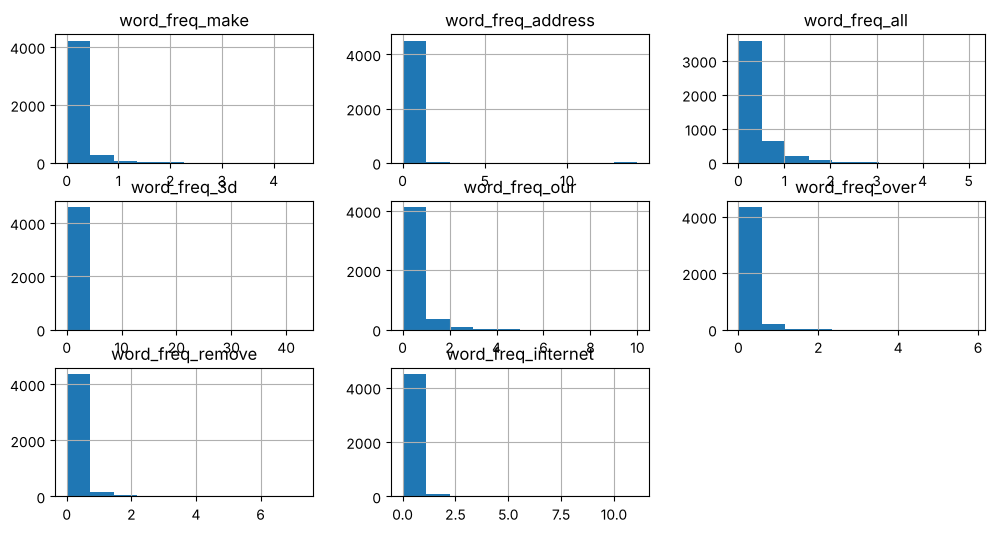

In [9]:
df.select_dtypes("number").iloc[:, :8].hist(figsize=(12, 6))
plt.show()

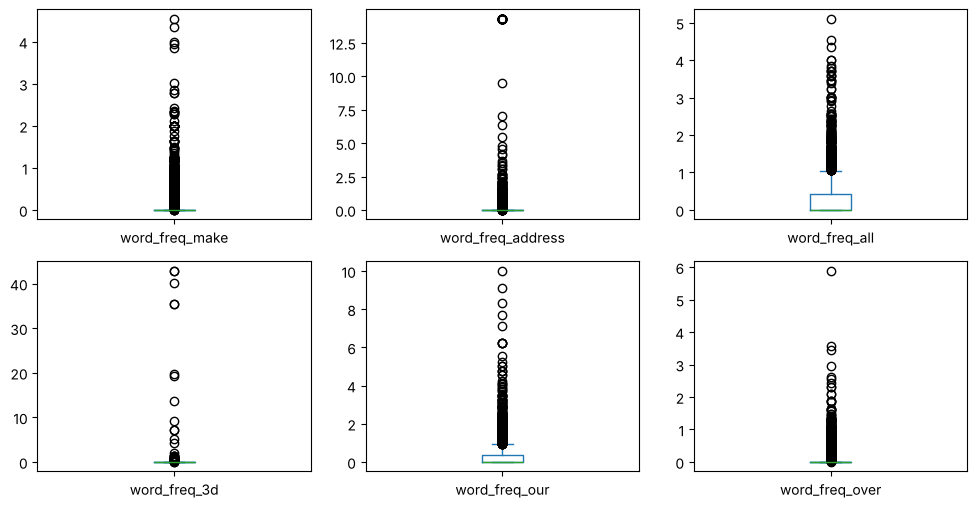

In [10]:
df.select_dtypes("number").iloc[:, :6].plot(
    kind="box", subplots=True, layout=(2, 3), figsize=(12, 6)
)
plt.show()

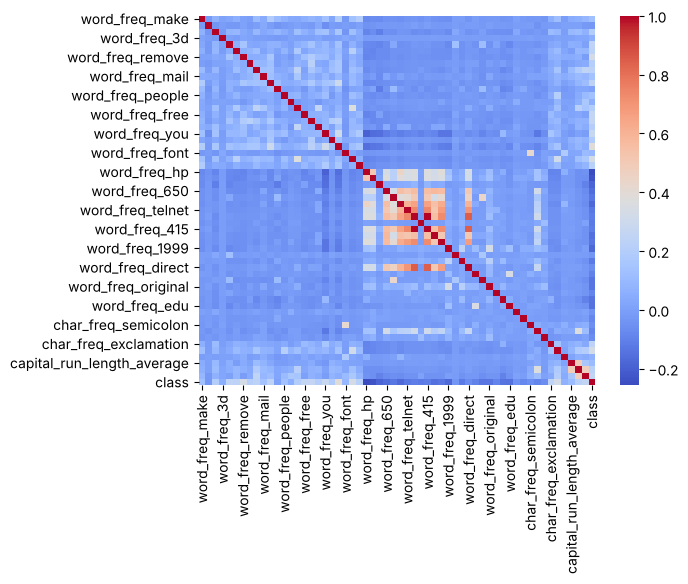

In [11]:
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm")
plt.show()

## 3. Preprocessing

In [12]:
df = df.drop_duplicates()

In [13]:
for col in df.columns.drop(TARGET):
    if df[col].dtype.kind in "if":
        df[col] = df[col].fillna(df[col].median())
    else:
        df[col] = df[col].fillna(df[col].mode()[0])

In [14]:
X = pd.get_dummies(df.drop(columns=TARGET), drop_first=True)

In [15]:
y = LabelEncoder().fit_transform(df[TARGET])
print(np.bincount(y) / len(y))

[0.60118765 0.39881235]


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [17]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [18]:
def evaluate(model):
    pred = model.predict(X_test)
    print("Accuracy :", round(accuracy_score(y_test, pred), 4))
    print("Precision:", round(precision_score(y_test, pred, average=AVG), 4))
    print("Recall   :", round(recall_score(y_test, pred, average=AVG), 4))
    print("F1       :", round(f1_score(y_test, pred, average=AVG), 4))

## 4. Decision Tree

In [19]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
evaluate(dt)

Accuracy : 0.9074
Precision: 0.8817
Recall   : 0.8869
F1       : 0.8843


In [20]:
dt_grid = {
    "max_depth": [None, 3, 5, 7, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "criterion": ["gini", "entropy"],
}

In [21]:
dt_gs = GridSearchCV(dt, dt_grid, cv=5, scoring=SCORING, n_jobs=-1)
dt_gs.fit(X_train, y_train)
print(dt_gs.best_params_)
print(dt_gs.best_score_)

{'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 10}
0.9207216899396388


In [22]:
best_dt = dt_gs.best_estimator_
evaluate(best_dt)

Accuracy : 0.905
Precision: 0.8832
Recall   : 0.878
F1       : 0.8806


## 5. KNN

In [23]:
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
evaluate(knn)

Accuracy : 0.9133
Precision: 0.9148
Recall   : 0.8631
F1       : 0.8882


In [24]:
knn_grid = {
    "n_neighbors": list(range(1, 10)),
    "algorithm": ["kd_tree", "ball_tree"],
}

In [25]:
knn_gs = GridSearchCV(knn, knn_grid, cv=5, scoring=SCORING, n_jobs=-1)
knn_gs.fit(X_train, y_train)
print(knn_gs.best_params_)
print(knn_gs.best_score_)

{'algorithm': 'kd_tree', 'n_neighbors': 3}
0.8957835282913214


In [26]:
best_knn = knn_gs.best_estimator_
evaluate(best_knn)

Accuracy : 0.9097
Precision: 0.9062
Recall   : 0.8631
F1       : 0.8841


## 6. SVM

In [27]:
svm = SVC(random_state=42)
svm.fit(X_train, y_train)
evaluate(svm)

Accuracy : 0.9323
Precision: 0.9319
Recall   : 0.8958
F1       : 0.9135


In [28]:
svm_grid = {
    "C": [0.1, 1, 10],
    "kernel": ["linear", "rbf"],
    "gamma": ["scale", "auto"],
}

In [29]:
svm_gs = GridSearchCV(svm, svm_grid, cv=5, scoring=SCORING, n_jobs=-1)
svm_gs.fit(X_train, y_train)
print(svm_gs.best_params_)
print(svm_gs.best_score_)

{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
0.9254809282146024


In [30]:
best_svm = svm_gs.best_estimator_
evaluate(best_svm)

Accuracy : 0.9335
Precision: 0.9294
Recall   : 0.9018
F1       : 0.9154


## 7. Grid Search vs Random Search

In [31]:
start = time.time()
grid_search = GridSearchCV(dt, dt_grid, cv=5, scoring=SCORING)
grid_search.fit(X_train, y_train)
grid_time = time.time() - start

In [32]:
start = time.time()
random_search = RandomizedSearchCV(
    dt,
    dt_grid,
    n_iter=10,
    cv=5,
    scoring=SCORING,
    random_state=42,
)
random_search.fit(X_train, y_train)
random_time = time.time() - start

In [33]:
print("Grid combinations:", len(grid_search.cv_results_["params"]))
print("Grid best score:", round(grid_search.best_score_, 4))
print("Grid time:", round(grid_time, 2))
print("Random combinations:", len(random_search.cv_results_["params"]))
print("Random best score:", round(random_search.best_score_, 4))
print("Random time:", round(random_time, 2))

Grid combinations: 90
Grid best score: 0.9207
Grid time: 11.5
Random combinations: 10
Random best score: 0.9142
Random time: 1.24


In [34]:
results = pd.DataFrame(grid_search.cv_results_)
fold_cols = [c for c in results.columns if c.startswith("split")]
print(results.loc[grid_search.best_index_, fold_cols])

split0_test_score    0.912463
split1_test_score    0.939169
split2_test_score    0.919881
split3_test_score    0.913819
split4_test_score    0.918276
Name: 50, dtype: float64


## 8. 5-fold Cross-Validation

In [35]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [36]:
models = {
    "Decision Tree": best_dt,
    "KNN": best_knn,
    "SVM": best_svm,
}

In [37]:
for name, model in models.items():
    s = cross_val_score(model, X_train, y_train, cv=cv5, scoring=SCORING)
    print(
        name,
        s.round(3),
        "mean:",
        round(s.mean(), 4),
        "std:",
        round(s.std(), 4),
    )

Decision Tree [0.911 0.927 0.901 0.92  0.93 ] mean: 0.9178 std: 0.0109


KNN [0.898 0.909 0.883 0.9   0.909] mean: 0.8999 std: 0.0098


SVM [0.921 0.942 0.898 0.941 0.941] mean: 0.9285 std: 0.0172


## 9. PCA vs No PCA

In [38]:
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)
print(X_train.shape[1], "->", pca.n_components_)

57 -> 48


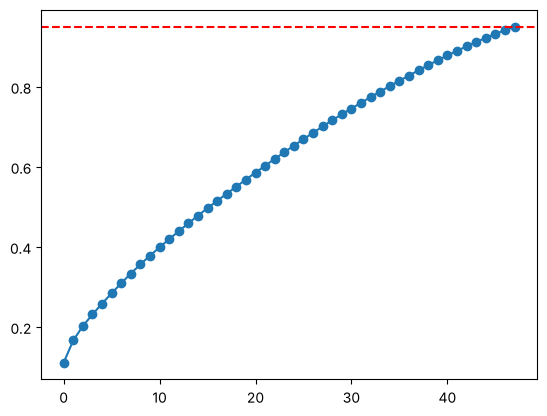

In [39]:
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker="o")
plt.axhline(0.95, color="red", linestyle="--")
plt.show()

In [40]:
for name, model in models.items():
    no_pca = cross_val_score(
        model, X_train, y_train, cv=cv5, scoring=SCORING
    ).mean()
    with_pca = cross_val_score(
        model, X_train_pca, y_train, cv=cv5, scoring=SCORING
    ).mean()
    print(name, "| no PCA:", round(no_pca, 4), "| PCA:", round(with_pca, 4))

Decision Tree | no PCA: 0.9178 | PCA: 0.8676


KNN | no PCA: 0.8999 | PCA: 0.9014


SVM | no PCA: 0.9285 | PCA: 0.9261


## 10. Statistical Significance

In [41]:
repeated_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

In [42]:
scores = {}
for name, model in models.items():
    scores[name] = cross_val_score(
        model, X_train, y_train, cv=repeated_cv, scoring=SCORING
    )
model_names = list(scores)
model_scores = list(scores.values())
print(pd.DataFrame(scores).mean().round(4))

Decision Tree    0.9167
KNN              0.8998
SVM              0.9275
dtype: float64


In [43]:
print("Friedman p:", friedmanchisquare(*model_scores)[1])
print("ANOVA p:", f_oneway(*model_scores)[1])

Friedman p: 1.0473454271059398e-05
ANOVA p: 1.9292316071734165e-07


In [44]:
means = [s.mean() for s in model_scores]
best = int(np.argmax(means))
print("Best model:", model_names[best])

Best model: SVM


In [45]:
alpha = 0.05 / (len(model_names) - 1)
for i in range(len(model_names)):
    if i == best:
        continue
    t_p = ttest_rel(model_scores[best], model_scores[i])[1]
    w_p = wilcoxon(model_scores[best], model_scores[i])[1]
    print(model_names[best], "vs", model_names[i])
    print("t-test p:", round(t_p, 4))
    print("wilcoxon p:", round(w_p, 4))
    print("significant:", max(t_p, w_p) < alpha)

SVM vs Decision Tree
t-test p: 0.002
wilcoxon p: 0.0045
significant: True
SVM vs KNN
t-test p: 0.0
wilcoxon p: 0.0001
significant: True


## 11. Class Imbalance

In [46]:
print(pd.Series(y_train).value_counts(normalize=True))

0    0.601247
1    0.398753
Name: proportion, dtype: float64


In [47]:
small = np.bincount(y_train).argmin()
big = np.bincount(y_train).argmax()
X_small = X_train[y_train == small]
X_big = X_train[y_train == big]

In [48]:
X_small_up = resample(
    X_small, replace=True, n_samples=len(X_big), random_state=42
)
X_over = np.vstack([X_big, X_small_up])
y_over = np.array([big] * len(X_big) + [small] * len(X_big))

In [49]:
X_big_down = resample(
    X_big, replace=False, n_samples=len(X_small), random_state=42
)
X_under = np.vstack([X_big_down, X_small])
y_under = np.array([big] * len(X_small) + [small] * len(X_small))

In [50]:
setups = {
    "original": (DecisionTreeClassifier(random_state=42), X_train, y_train),
    "class_weight": (
        DecisionTreeClassifier(class_weight="balanced", random_state=42),
        X_train,
        y_train,
    ),
    "oversample": (DecisionTreeClassifier(random_state=42), X_over, y_over),
    "undersample": (DecisionTreeClassifier(random_state=42), X_under, y_under),
}

In [51]:
for name, (model, X_fit, y_fit) in setups.items():
    pred = model.fit(X_fit, y_fit).predict(X_test)
    print(name)
    print("accuracy:", round(accuracy_score(y_test, pred), 4))
    print("recall:", round(recall_score(y_test, pred, average=AVG), 4))
    print("f1:", round(f1_score(y_test, pred, average=AVG), 4))

original
accuracy: 0.9074
recall: 0.8869
f1: 0.8843
class_weight
accuracy: 0.9062
recall: 0.8839
f1: 0.8826


oversample
accuracy: 0.8907
recall: 0.8571
f1: 0.8623
undersample
accuracy: 0.8884
recall: 0.8929
f1: 0.8646


## 12. Final Evaluation

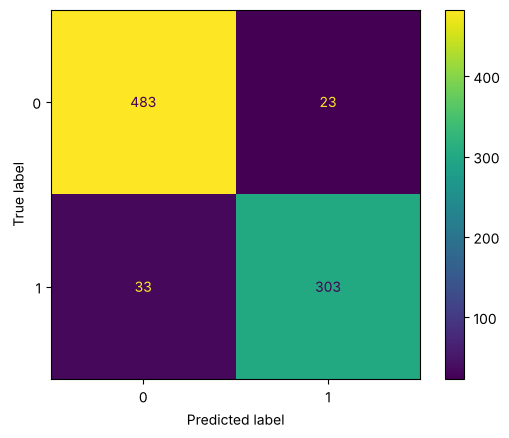

In [52]:
best_model = models[model_names[best]]
pred = best_model.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.show()

ROC AUC: 0.9776


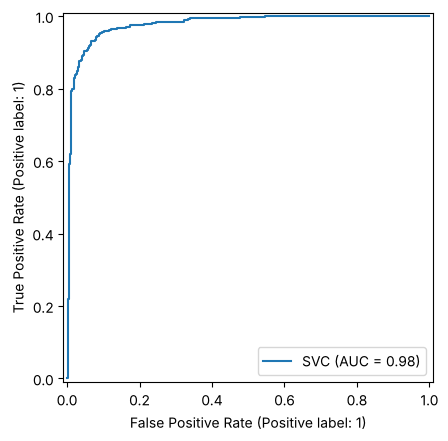

In [53]:
roc = RocCurveDisplay.from_estimator(best_model, X_test, y_test)
print("ROC AUC:", round(roc.roc_auc, 4))
plt.show()